# Seismic waveforms: QC, filtering and first picks

**Level 1 — Foundations and measurement** · 45–60 min

## Objectives
- Inspect provenance, units, channel order, sampling and analyst-reference labels.
- Apply the product Butterworth filter and classical STA/LTA detector using editable controls.
- Measure pick residuals against analyst references while varying synthetic noise, passband and trigger threshold.

## Setup

Run from repository root in the pinned notebook environment:
pip install numpy==2.2.6 scipy==1.15.2 matplotlib==3.10.8

The experiment cell prints active package versions.

## Data
Input: one trace from the committed STEAD-derived browser subset. Samples are normalized, unrestituted instrument counts; this artifact lacks response metadata for physical ground-motion units. Analyst picks are references, not geological truth. Added noise is synthetic and seeded. No result describes a new field observation.

## Method

For sample interval Δt and index n, time is tₙ=nΔt. Inspect acquisition and data contracts before filtering: a plausible trace cannot repair wrong component orientation, clock, response or datum.

The product path in data-pipeline/waveform_processing.py removes instrument response when MiniSEED and StationXML permit, applies a fourth-order SOS Butterworth band-pass with forward-backward filtering, then forms a short/long-window energy ratio. For three components x[n], the characteristic is approximately C[n]=STA(Σc x_c²)/LTA(Σc x_c²). An upward threshold crossing marks an onset. The second sufficiently separated crossing is provisionally called S; STA/LTA is not a phase classifier.

This browser trace is already normalized and has no response metadata. We reproduce the product SOS Butterworth filter design and use its actual STA/LTA picker, but do not load the waveform engine's pinned ObsPy contract or execute raw MiniSEED ingestion, response correction or complete M08 QC. Add one seeded standard-normal realization at several fractions of trace standard deviation. Compare picks with supplied analyst references; absolute residuals and misses are agreement diagnostics on one trace, not accuracy estimates.

### Questions
1. Which channel/window dominates the energy ratio, and what does the filter remove?
2. Does a higher threshold reduce early triggers or miss an annotated onset?
3. Why does smaller analyst-pick residual not establish physical accuracy?

### Experiment 1 — edit controls and compare the sweep

Noise settings reuse one seeded realization to isolate amplitude. Filter and trigger controls vary separately. Set the band to None to bypass filtering.

In [1]:
from importlib.metadata import version
print("Runtime versions:", {name: version(name) for name in ['numpy', 'scipy', 'matplotlib']})
# Reproducible notebook experiment cell.
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'data').is_dir() and (p/'data-pipeline').is_dir())
sys.path.insert(0, str(root/'data-pipeline'))
from scipy.signal import butter, sosfiltfilt
from phase_picking import classical_stalta_picks
base = root/'data/derived/phase/browser-assets/stead'
manifest = json.loads((base/'manifest.json').read_text(encoding='utf-8'))
record = manifest['records'][0]
raw = np.fromfile(base/record['waveform_file'], dtype='<f4').reshape(manifest['input']['shape'])[0].T.astype(float)
fs = float(manifest['input']['sample_rate_hz']); dt = 1/fs
labels = {'P': record['analyst_p_s'], 'S': record['analyst_s_s']}
bench = json.loads((root/'data/derived/phase/stead-heldout-benchmark.json').read_text(encoding='utf-8'))
pars = bench['classical_parameters']
print('Trace', record['trace_id'], raw.shape, 'sample x component; fs=', fs, 'Hz; units=', manifest['input']['unit'])
print('Channels', manifest['input']['component_order'], '| analyst reference times (s):', labels)
FILTER_BAND_HZ = (1.0, 12.0)  # set None to bypass
ADDED_NOISE_FRACTION = 0.25    # relative to trace standard deviation
TRIGGER_RATIO = float(pars['trigger_ratio'])
STA_SECONDS = float(pars['STA_s']); LTA_SECONDS = float(pars['LTA_s'])
MINIMUM_PS_SECONDS = float(pars['minimum_PS_s'])
SEED = 20261027
noise_unit = np.random.default_rng(SEED).standard_normal(raw.shape)
noise = noise_unit * np.std(raw)

def condition(values, band):
    if band is None: return values.copy(), 0
    out = np.empty_like(values); pads = []
    for c in range(values.shape[1]):
        sos = butter(4, band, btype='bandpass', fs=fs, output='sos')
        pad = 3*(2*len(sos)+1-min(int((sos[:,2]==0).sum()),int((sos[:,5]==0).sum())))
        out[:, c] = sosfiltfilt(sos, values[:, c], padtype='odd', padlen=pad)
        if not np.isfinite(out[:,c]).all(): raise ValueError('non-finite filter output')
        pads.append(pad)
    return out, max(pads)

def trial(band, noise_fraction, threshold):
    filtered, pad = condition(raw + noise_fraction*noise, band)
    picks = classical_stalta_picks(filtered, sample_interval_s=dt, threshold=threshold,
        sta_s=STA_SECONDS, lta_s=LTA_SECONDS, minimum_ps_s=MINIMUM_PS_SECONDS)
    row = {'band_Hz': 'off' if band is None else f'{band[0]:g}-{band[1]:g}',
           'added_noise_fraction': noise_fraction, 'threshold': threshold, 'filter_pad_samples': pad}
    for phase in ('P', 'S'):
        t = picks[phase]
        row[f'{phase}_pick_s'] = np.nan if t is None else t
        row[f'{phase}_abs_residual_s'] = np.nan if t is None else abs(t-labels[phase])
        row[f'{phase}_detected'] = t is not None
    return filtered, picks, row

configs = [(None,0,TRIGGER_RATIO), ((1,12),0,TRIGGER_RATIO),
           ((1,12),.25,TRIGGER_RATIO), ((3,10),.75,TRIGGER_RATIO),
           ((3,10),.75,3.2)]
table = pd.DataFrame([trial(*cfg)[2] for cfg in configs])
display(table.round(4))
selected, picks, _ = trial(FILTER_BAND_HZ, ADDED_NOISE_FRACTION, TRIGGER_RATIO)
print('Selected controls:', FILTER_BAND_HZ, ADDED_NOISE_FRACTION, TRIGGER_RATIO,
      'STA/LTA/min P-S:', STA_SECONDS, LTA_SECONDS, MINIMUM_PS_SECONDS, 'seed:', SEED)
print('Selected picks (s):', picks)
print('Missing pick means missed onset; the second eligible trigger is only provisionally named S.')


Runtime versions: {'numpy': '2.2.6', 'scipy': '1.15.2', 'matplotlib': '3.10.8'}
Trace B917.PB_20110107214856_EV (6000, 3) sample x component; fs= 100.0 Hz; units= dimensionless normalized instrument counts
Channels ['E', 'N', 'Z'] | analyst reference times (s): {'P': 7.0, 'S': 12.77}


,band_Hz,added_noise_fraction,threshold,filter_pad_samples,P_pick_s,P_abs_residual_s,P_detected,S_pick_s,S_abs_residual_s,S_detected
0,off,0.00,2.5,0,1.19,5.81,True,7.02,5.75,True
1,1-12,0.00,2.5,27,1.19,5.81,True,6.95,5.82,True
2,1-12,0.25,2.5,27,6.99,0.01,True,12.81,0.04,True
3,3-10,0.75,2.5,27,4.55,2.45,True,5.50,7.27,True
4,3-10,0.75,3.2,27,7.02,0.02,True,12.81,0.04,True


Selected controls: (1.0, 12.0) 0.25 2.5 STA/LTA/min P-S: 0.12 1.2 0.4 seed: 20261027
Selected picks (s): {'P': 6.99, 'S': 12.81}
Missing pick means missed onset; the second eligible trigger is only provisionally named S.


### Diagnostic 2 — inspect the selected trace and measured timing outcomes

Markers show supplied analyst references and detector output. The displayed trace follows the selected noise and filter controls. Compare the numeric residual table, not just the plot.

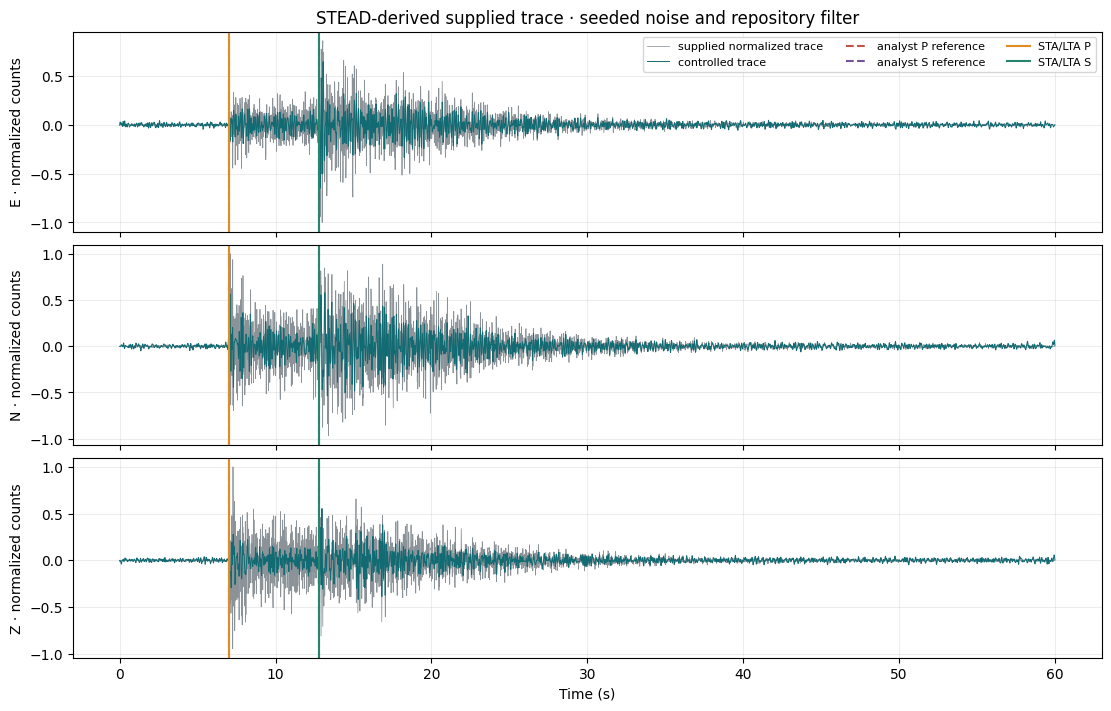

Single-trace analyst agreement is not a population score or field-truth claim.


In [2]:
# Reproducible notebook experiment cell.
time_s = np.arange(len(raw))*dt
names = manifest['input']['component_order']
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True, constrained_layout=True)
for c, ax in enumerate(axes):
    ax.plot(time_s, raw[:, c], color='#8b9398', lw=.55, label='supplied normalized trace')
    ax.plot(time_s, selected[:, c], color='#126b73', lw=.7, label='controlled trace')
    ax.axvline(labels['P'], color='#c45442', ls='--', label='analyst P reference')
    ax.axvline(labels['S'], color='#76529b', ls='--', label='analyst S reference')
    for phase, color in (('P','#e28b22'),('S','#24866c')):
        if picks[phase] is not None: ax.axvline(picks[phase], color=color, label=f'STA/LTA {phase}')
    ax.set_ylabel(f'{names[c]} · normalized counts'); ax.grid(alpha=.22)
axes[0].legend(ncol=3, fontsize=8); axes[-1].set_xlabel('Time (s)')
axes[0].set_title('STEAD-derived supplied trace · seeded noise and repository filter')
plt.show()
print('Single-trace analyst agreement is not a population score or field-truth claim.')

## Results

Use the generated sweep table for detections and absolute P/S residuals. State which settings changed the outcome; one trace is not a benchmark.

## Summary
Report the sampling/unit contract, controlled variable, measured residual or missed pick, and why this does not establish field accuracy.

## References
- [ObsPy Stream and waveform metadata](https://docs.obspy.org/packages/autogen/obspy.core.stream.stream.html)
- Committed trace and provenance manifest: data/derived/phase/browser-assets/stead/manifest.json
- Product filter design: data-pipeline/waveform_processing.py
- Product detector: data-pipeline/phase_picking.py